In [47]:
from tensorflow.keras.layers import Dense
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt
import numpy as np

prepare the data

In [49]:
X,Y=load_iris(return_X_y=True)
X=X[:100]
Y=Y[:100]
scaler=StandardScaler()
X_Train,X_Test,Y_Train,Y_Test=train_test_split(X,Y,test_size=0.2,random_state=42)
X_Train=scaler.fit_transform(X_Train)
X_Test=scaler.fit_transform(X_Test)

Gradient Descent

In [50]:
model=Sequential([Dense(1,activation='sigmoid')])
model.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])
history=model.fit(X_Train,Y_Train,epochs=50,batch_size=len(X_Train),verbose=0)
pre=model.predict(X_Test)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


In [51]:
test_loss, test_acc = model.evaluate(X_Test, Y_Test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 0.3126
Test Accuracy: 100.00%


In [52]:
loss=history.history['loss']
accuracy=history.history['accuracy']


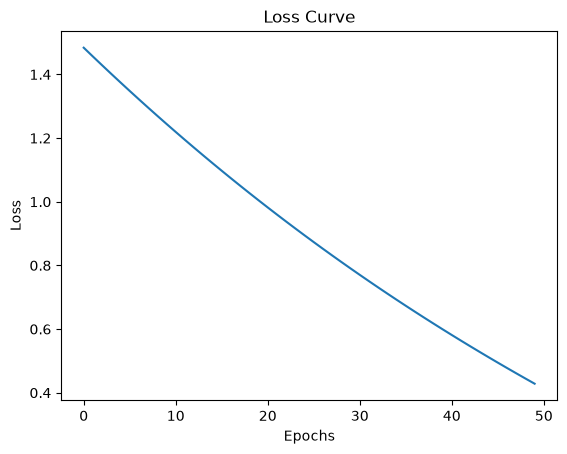

In [40]:

# 2. ارسم منحنى الخسارة (Loss)
plt.plot(history.history['loss'])
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

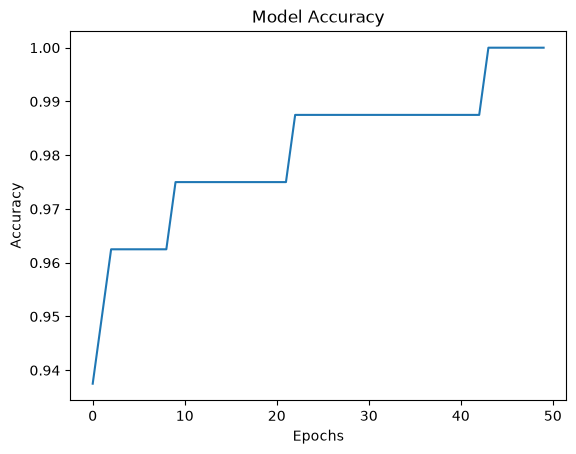

In [53]:
plt.plot(history.history['accuracy'])
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

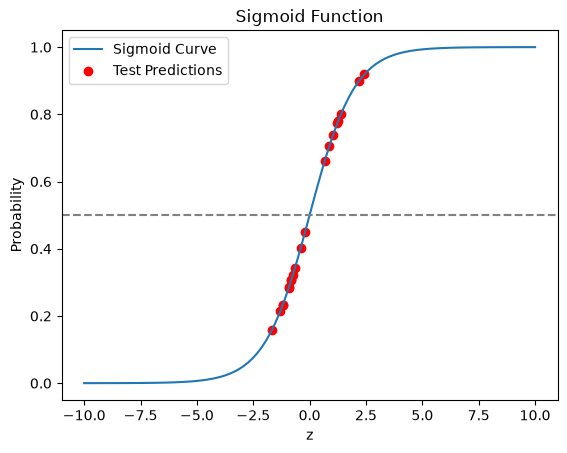

In [54]:
w, b = model.layers[0].get_weights()   # استخراج الأوزان من النموذج
z_test = np.dot(X_Test, w) + b         # حساب z لبيانات الاختبار

z_line = np.linspace(-10, 10, 100)     # نقاط لرسم منحنى السيجمويد السلس
sigmoid = 1 / (1 + np.exp(-z_line))

plt.plot(z_line, sigmoid, label="Sigmoid Curve")
plt.scatter(z_test, pre, color='red', label="Test Predictions")
